Рекомендована потужність кондиціонера: 55.2 %


C:\Users\Cніжана\OneDrive\Рабочий стол\fuzzy-tutorial-main\fuzzy-tutorial-main\venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


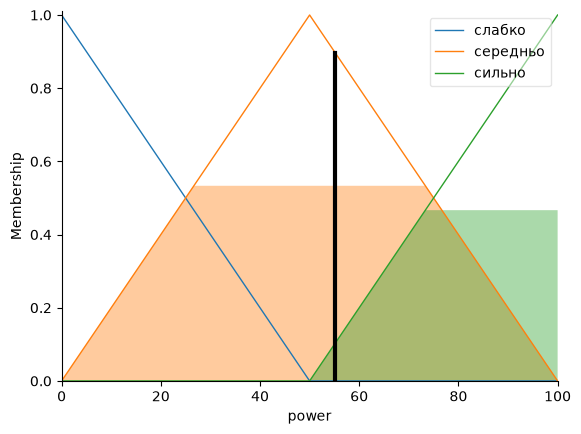

In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# 1. СТВОРЮЄМО ЗМІННІ 
# Температура від 10 до 40 градусів
temperature = ctrl.Antecedent(np.arange(10, 41, 1), 'temperature')
# Кількість людей у кімнаті від 0 до 10
people = ctrl.Antecedent(np.arange(0, 11, 1), 'people')
# Потужність кондиціонера від 0 до 100 відсотків
power = ctrl.Consequent(np.arange(0, 101, 1), 'power')

# 2. РОЗБИВАЄМО НА КАТЕГОРІЇ 
# Програма сама поділить температуру і людей на 3 рівні: низький, середній, високий
temperature.automf(3, names=['холодно', 'тепло', 'спекотно'])
people.automf(3, names=['мало', 'нормально', 'багато'])

# Для кондиціонера прописуємо межі вручну (слабко, середньо, сильно)
power['слабко'] = fuzz.trimf(power.universe, [0, 0, 50])
power['середньо'] = fuzz.trimf(power.universe, [0, 50, 100])
power['сильно'] = fuzz.trimf(power.universe, [50, 100, 100])

# 3. ЗАДАЄМО ПРАВИЛА 
rule1 = ctrl.Rule(temperature['холодно'] | people['мало'], power['слабко'])
rule2 = ctrl.Rule(temperature['тепло'], power['середньо'])
rule3 = ctrl.Rule(temperature['спекотно'] & people['багато'], power['сильно'])
rule4 = ctrl.Rule(temperature['спекотно'] & people['нормально'], power['сильно'])

# 4. ЗАПУСКАЄМО МОЗОК КОНДИЦІОНЕРА
ac_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4])
ac_sim = ctrl.ControlSystemSimulation(ac_ctrl)

# 5. ТЕСТУЄМО НА РЕАЛЬНИХ ДАНИХ!
# Задаємо комп'ютеру ситуацію: в кімнаті 32 градуси і 7 людей
ac_sim.input['temperature'] = 32
ac_sim.input['people'] = 7

# Просимо комп'ютер порахувати результат
ac_sim.compute()

# Виводимо результат на екран
print("Рекомендована потужність кондиціонера:", round(ac_sim.output['power'], 1), "%")
power.view(sim=ac_sim)